# Lab 4: Character-level Language Model using RNN

Train a `SimpleRNN` on a small text file (<= 50 KB) to predict the 41st character from 40 preceding characters, then generate new text in the style of the training data.

## 1. Load text and build char-to-index / index-to-char mappings

In [1]:
import os, numpy as np
from tensorflow import keras

np.random.seed(42)
keras.utils.set_random_seed(42)

SEQ_LEN, STEP = 40, 1
PATH = "sample.txt"
assert os.path.getsize(PATH) <= 50 * 1024, "input must be <= 50 KB"

text = open(PATH, encoding="utf-8").read()
chars = sorted(set(text))
char_to_idx = {c: i for i, c in enumerate(chars)}
idx_to_char = {i: c for c, i in char_to_idx.items()}
print(f"Corpus: {len(text)} chars, vocabulary: {len(chars)} unique chars")
print(chars)

I0000 00:00:1793590470.569960     602 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793590484.736724     602 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1793590493.053352     602 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Corpus: 2444 chars, vocabulary: 49 unique chars
['\n', ' ', '!', "'", ',', '-', '.', ':', ';', '?', 'A', 'B', 'D', 'F', 'H', 'I', 'L', 'M', 'N', 'O', 'R', 'S', 'T', 'W', 'Y', 'a', 'b', 'c', 'd', 'e', 'f', 'g', 'h', 'i', 'j', 'k', 'l', 'm', 'n', 'o', 'p', 'r', 's', 't', 'u', 'v', 'w', 'x', 'y']


## 2-3. Create training sequences (40 chars -> 41st) and vectorize

In [2]:
inputs, targets = [], []
for i in range(0, len(text) - SEQ_LEN, STEP):
    inputs.append(text[i:i + SEQ_LEN])
    targets.append(text[i + SEQ_LEN])

vocab = len(chars)
x = np.zeros((len(inputs), SEQ_LEN, vocab), dtype=np.float32)
y = np.zeros((len(inputs), vocab), dtype=np.float32)
for n, (window, nxt) in enumerate(zip(inputs, targets)):
    for t, ch in enumerate(window):
        x[n, t, char_to_idx[ch]] = 1.0
    y[n, char_to_idx[nxt]] = 1.0

print("x:", x.shape, " y:", y.shape)
print(repr(inputs[0]), "->", repr(targets[0]))

x: (2404, 40, 49)  y: (2404, 49)
"Shall I compare thee to a summer's day?\n" -> 'T'


## 4. Build the RNN model
The first `SimpleRNN` returns the whole sequence so the second can consume it.

In [3]:
model = keras.Sequential([
    keras.layers.Input(shape=(SEQ_LEN, vocab)),
    keras.layers.SimpleRNN(256, return_sequences=True),
    keras.layers.SimpleRNN(256),
    keras.layers.Dense(vocab, activation="softmax"),
])
model.compile(loss="categorical_crossentropy",
              optimizer=keras.optimizers.Adam(learning_rate=1e-3, clipnorm=1.0),
              metrics=["accuracy"])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)          │ (None, 40, 256)        │        78,336 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_1 (SimpleRNN)        │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 49)             │        12,593 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 222,257 (868.19 KB)

 Trainable params: 222,257 (868.19 KB)

 Non-trainable params: 0 (0.00 B)

## 5. Train the model

In [4]:
history = model.fit(x, y, batch_size=64, epochs=100, verbose=2)

Epoch 1/100


38/38 - 4s - 92ms/step - accuracy: 0.1423 - loss: 3.2510


Epoch 2/100


38/38 - 1s - 28ms/step - accuracy: 0.1797 - loss: 3.0637


Epoch 3/100


38/38 - 1s - 27ms/step - accuracy: 0.2151 - loss: 2.8688


... (190 outputs left out)

Epoch 99/100


38/38 - 1s - 36ms/step - accuracy: 1.0000 - loss: 3.5404e-04


Epoch 100/100


38/38 - 1s - 27ms/step - accuracy: 1.0000 - loss: 3.4655e-04


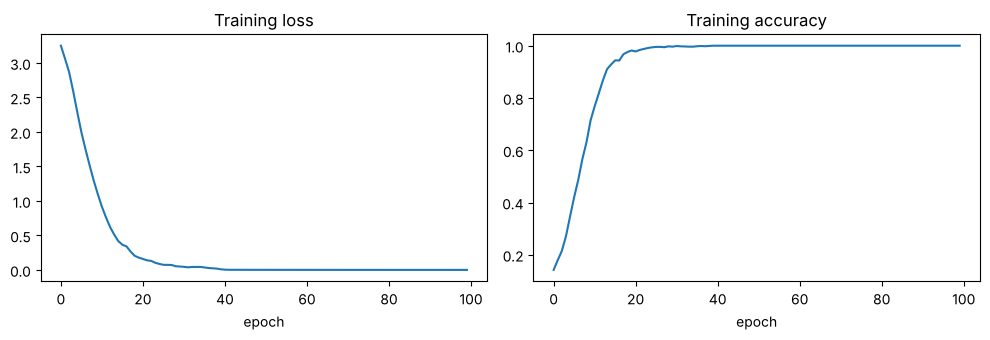

In [5]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(history.history["loss"]); ax[0].set_title("Training loss"); ax[0].set_xlabel("epoch")
ax[1].plot(history.history["accuracy"]); ax[1].set_title("Training accuracy"); ax[1].set_xlabel("epoch")
plt.tight_layout(); plt.show()

## 6. Text generation function
Temperature sampling: low = conservative, high = more random.

In [6]:
def sample(probs, temperature=1.0):
    p = np.log(np.asarray(probs, dtype=np.float64) + 1e-9) / temperature
    p = np.exp(p - p.max()); p /= p.sum()
    return int(np.random.choice(len(p), p=p))

def generate(seed, length=400, temperature=0.7):
    window = "".join(c for c in seed if c in char_to_idx)[-SEQ_LEN:]
    out = window
    for _ in range(length):
        xi = np.zeros((1, SEQ_LEN, vocab), dtype=np.float32)
        pad = SEQ_LEN - len(window)
        for t, ch in enumerate(window):
            xi[0, pad + t, char_to_idx[ch]] = 1.0
        nxt = idx_to_char[sample(model.predict(xi, verbose=0)[0], temperature)]
        out += nxt
        window = (window + nxt)[-SEQ_LEN:]
    return out

## 7. Generate new text and validate

In [7]:
seed = text[:SEQ_LEN]
for temp in (0.3, 0.7, 1.0):
    print(f"--- temperature {temp} ---")
    print(generate(seed, temperature=temp))
    print()

--- temperature 0.3 ---


Shall I compare thee to a summer's day?
Thou art more lovely and more temperate:
Rough winds do shake the darling buds of May,
And summer's lease hath all too short a date;
Sometime too hot the eye of heaven shines,
And often is his gold complexion dimm'd;
And every fair from fair sometime declines,
By chance or nature's changing course untrimm'd;
But thy eternal summer shall not fade,
Nor lose possession of that fair thou ow'st;
Nor sh

--- temperature 0.7 ---


Shall I compare thee to a summer's day?
Thou art more lovely and more temperate:
Rough winds do shake the darling buds of May,
And summer's lease hath all too short a date;
Sometime too hot the eye of heaven shines,
And often is his gold complexion dimm'd;
And every fair from fair sometime declines,
By chance or nature's changing course untrimm'd;
But thy eternal summer shall not fade,
Nor lose possession of that fair thou ow'st;
Nor sh

--- temperature 1.0 ---


Shall I compare thee to a summer's day?
Thou art more lovely and more temperate:
Rough winds do shake the darling buds of May,
And summer's lease hath all too short a date;
Sometime too hot the eye of heaven shines,
And often is his gold complexion dimm'd;
And every fair from fair sometime declines,
By chance or nature's changing course untrimm'd;
But thy eternal summer shall not fade,
Nor lose possession of that fair thou ow'st;
Nor sh



In [8]:
gen = generate(seed, length=500, temperature=0.5)[SEQ_LEN:]
train_words = set(text.lower().split())
words = gen.lower().split()
hit = sum(w in train_words for w in words) / max(len(words), 1)
print(f"{hit:.0%} of generated words appear in the training text")

99% of generated words appear in the training text


**Observation.** The model reproduces the vocabulary, line breaks, punctuation and rhythm of the sonnets. Lower temperatures give near-verbatim lines (the corpus is only ~2.4 KB, so the network largely memorises it); higher temperatures give more varied but noisier text. A larger corpus (up to 50 KB) would produce less memorised, more novel output.